In [1]:
# ++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
#  Copyright (c) 2023. Mohamed Reda Bouadjenek, Deakin University              +
#           Email:  reda.bouadjenek@deakin.edu.au                              +
#                                                                              +
#  Licensed under the Apache License, Version 2.0 (the "License");             +
#   you may not use this file except in compliance with the License.           +
#    You may obtain a copy of the License at:                                  +
#                                                                              +
#                 http://www.apache.org/licenses/LICENSE-2.0                   +
#                                                                              +
#    Unless required by applicable law or agreed to in writing, software       +
#    distributed under the License is distributed on an "AS IS" BASIS,         +
#    WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.  +
#    See the License for the specific language governing permissions and       +
#    limitations under the License.                                            +
#                                                                              +
# ++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


# Introduction

Welcome to your assignment this week! 


To deepen our comprehension of safety in AI, this assignment delves into a practical scenario involving **Image Classification** for traffic signs.





<img src="images/0_SkE_FOCh8qGP9Zqh.png" width="450"/> 

In the realm of artificial intelligence, ensuring safety stands as a paramount concern, particularly when the technology is harnessed for critical applications like autonomous driving vehicles. One example is the recognition of traffic signs, where the consequences of inaccurate predictions can reverberate dramatically, potentially resulting in tragic loss of life. In light of these profound implications, this assignment delves into the imperative topic of safety in AI, centering on the vital context of image classification for traffic signals.





Through an examination of safety within the realm of traffic sign classification, our objective is to unveil and mitigate potential risks inherent in such systems. This endeavor is driven by the pursuit of a more profound comprehension of how AI algorithms can inadvertently introduce risks and uncertainties.



Run the following cell to load the packages you will need for this assignment.


In [2]:
from pathlib import Path
import os, random, collections, itertools
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import models, layers, optimizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator, DirectoryIterator
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, balanced_accuracy_score, accuracy_score, classification_report, roc_auc_score
try:
    from tqdm.auto import trange
except ImportError:
    def trange(n, **kwargs):
        return range(n)
from IPython.display import display, Markdown
SEED = 1337
keras.utils.set_random_seed(SEED)
# Limit CPU threads to avoid oversubscription in shared notebook environments.
try:
    tf.config.threading.set_intra_op_parallelism_threads(4)
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    pass
sns.set_theme(style='whitegrid')
print('TensorFlow:', tf.__version__)
print('GPU available:', bool(tf.config.list_physical_devices('GPU')))


TensorFlow: 2.21.0
GPU available: False


# Preprocessing


We use a traffic sign dataset that is composed of 48 folders (one for each sign) with 20-500 images in each folder. The total number of images is about 10,000.

For reading these images, we use `DirectoryIterator` in `tf.keras.preprocessing.image` that is an iterator capable of reading images from a directory on disk and is capable to extract labels. We also use `ImageDataGenerator` to split this dataset into training and validation set, this later is used to tune the hyperparameters of our model.


In [3]:
'''
    Split train and validation.
'''
# We define the size of input images to 64x64 pixels.
image_size = (64, 64)
# We define the batch size
batch_size = 64

# Create an image generator with a fraction of 40% images reserved for validation:
image_generator = ImageDataGenerator(validation_split=0.4)

# Now, we create a training data iterator by creating batchs of images of the same size as 
# defined previously, i.e., each image is resized in a 64x64 pixels format.
train_ds =  DirectoryIterator(
    "traffic_sign_dataset/",
    image_generator,
    class_mode='categorical',
    seed=1337,
    target_size=image_size,
    batch_size=batch_size,
    subset = 'training',
)

# Similarly, we create a validation data iterator by creating batchs of images of the same size as 
# defined previously, i.e., each image is resized in a 64x64 pixels format.
val_ds = DirectoryIterator(
    "traffic_sign_dataset/",
    image_generator,
    class_mode='categorical',
    seed=1337,
    target_size=image_size,
    batch_size=batch_size,
    subset = 'validation',
    shuffle=False
)

# We save the list of classes (labels).
class_names = list(train_ds.class_indices.keys())

# We also save the number of labels.
num_classes = train_ds.num_classes


Found 5815 images belonging to 48 classes.
Found 3846 images belonging to 48 classes.


# Exploring the data

Now, we do data exploration to show you samples of the images and their labels and some statistics to help you in understanding the data.

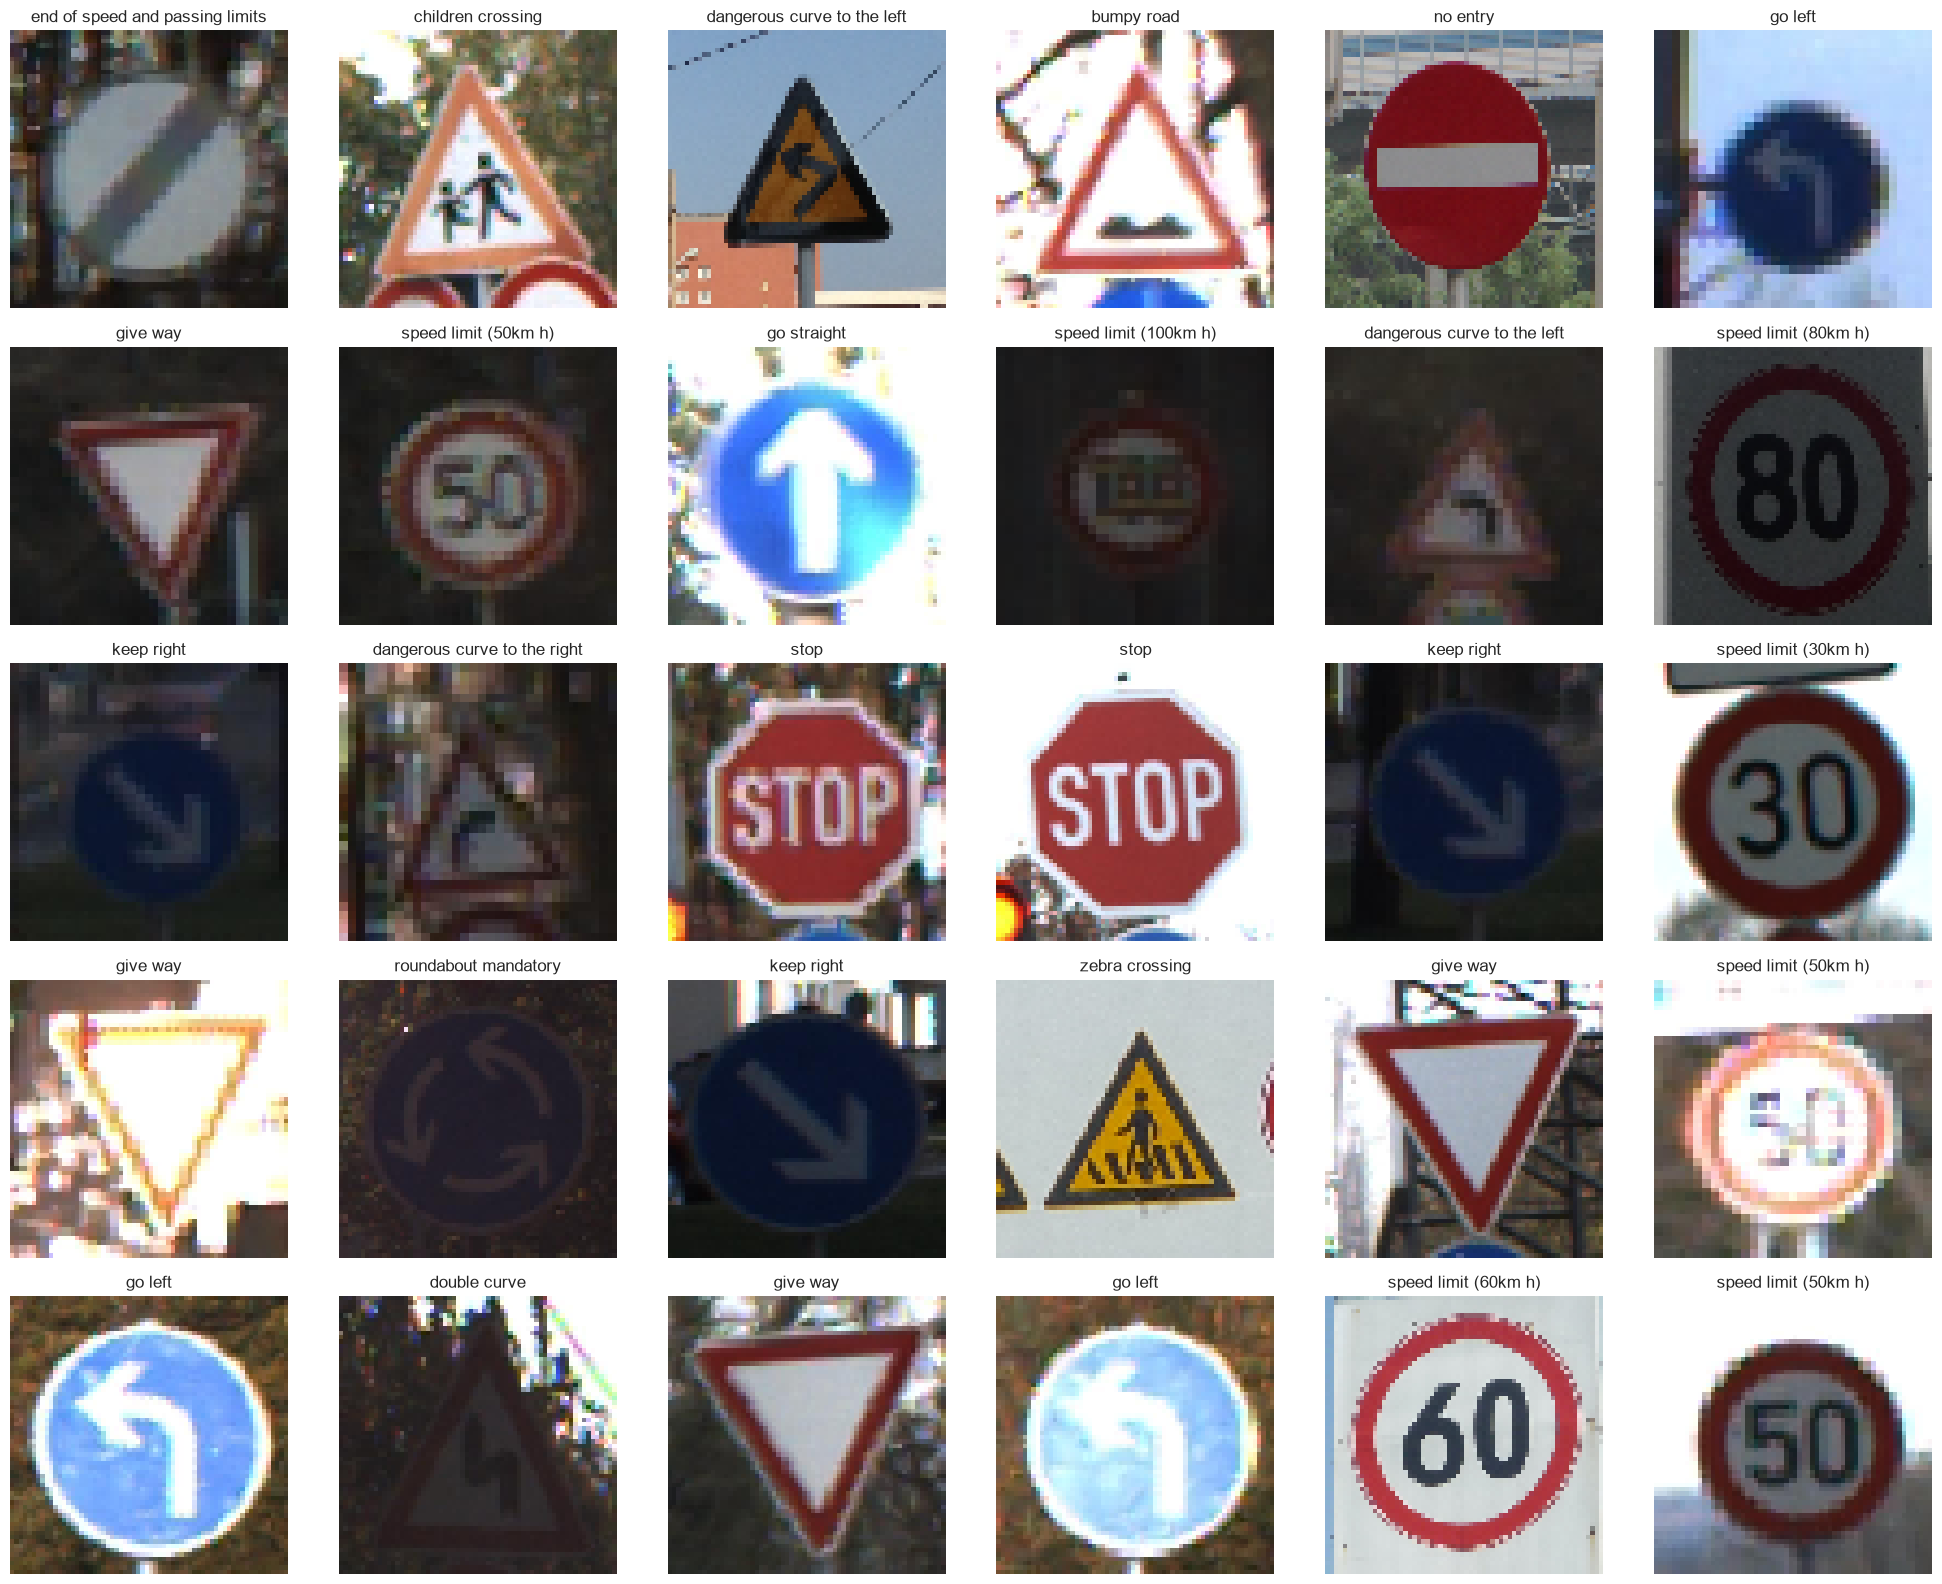

In [5]:
# Retrieve one batch of images and their one-hot encoded labels
images, labels = train_ds[0]

plt.figure(figsize=(20, 16))

for i in range(min(30, len(images))):
    plt.subplot(5, 6, i + 1)
    plt.imshow(images[i].astype("uint8"))

    label_index = np.argmax(labels[i])
    plt.title(class_names[label_index].replace("_", " "))
    plt.axis("off")

plt.tight_layout()
plt.show()

# Designing the model


We now design the architecture for the task.

In [7]:
model = models.Sequential(name='traffic_sign_cnn')
model.add(keras.Input(shape=image_size + (3,)))
model.add(layers.Rescaling(1./255))


## <span style="color:red"><b>TASK 1</b></span>


Define a convolutional neural network (CNN) architecture as follows:

1. CNN Block 1:
    - Add a dropout layer with a dropout rate of 0.25. Dropout is a regularization technique that randomly sets a fraction of input units to 0 during training, which helps prevent overfitting.
    - Add a convolutional layer with 16 filters, each having a 5x5 receptive field. The activation function used is ReLU (Rectified Linear Unit), and "same" padding ensures that the output size remains the same as the input size.
    - Add a max-pooling layer with a 2x2 pool size. Max-pooling reduces the spatial dimensions of the previous layer's output, helping to retain important features while reducing computational complexity.

2. CNN Block 2:
    - Add another dropout layer with a dropout rate of 0.25. 
    - Similar to the first convolutional layer, add another convolutional layer with 32 filters, each having a 5x5 receptive field and ReLU activation.
    - Add another max-pooling layer  after the second convolutional layer with a 2x2 pool size.

3. CNN Block 3:
    - Add another dropout layer with a dropout rate of 0.25.

    - Add a third convolutional layer with 32 filters, each having a 5x5 receptive field and ReLU activation.

    - Add another max-pooling layer after the third convolutional layer with a 2x2 pool size.

4. CNN Block 4:    
    - Add another dropout layer with a dropout rate of 0.25.
    - Add a fourth convolutional layer with 32 filters, each having a 5x5 receptive field and ReLU activation.
    - Add another max-pooling layer after the third convolutional layer with a 2x2 pool size.



In [8]:
# Task 1: four CNN blocks, each with dropout, convolution, and pooling.
for filters in [16, 32, 32, 32]:
    model.add(layers.Dropout(0.25))
    model.add(layers.Conv2D(filters, (5, 5), activation='relu', padding='same'))
    model.add(layers.MaxPooling2D(pool_size=(2, 2)))

In [9]:
model.add(layers.Flatten())
model.add(layers.Dropout(0.25))
model.add(layers.Dense(num_classes, activation='softmax'))
model.summary()
model.compile(optimizer=optimizers.RMSprop(learning_rate=0.001),
              loss='categorical_crossentropy', metrics=['accuracy'])


Model: "traffic_sign_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)                │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 64, 64, 16)          │           1,216 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 32, 32, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32, 32, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 32, 32, 32)          │          12,832 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 16, 16, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 16, 16, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 16, 16, 32)          │          25,632 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 8, 8, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 8, 8, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 8, 8, 32)            │          25,632 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 4, 4, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 48)                  │          24,624 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 89,936 (351.31 KB)

 Trainable params: 89,936 (351.31 KB)

 Non-trainable params: 0 (0.00 B)

# Traning

Let's now starting the training process.

In [10]:
# Start the trining by defining the number of epochs to train, the traing set and the validation set.
history = model.fit(
    train_ds, 
    epochs=50, 
    validation_data=val_ds,
)


Epoch 1/50
91/91 ━━━━━━━━━━━━━━━━━━━━ 45s 470ms/step - accuracy: 0.0782 - loss: 3.5536 - val_accuracy: 0.1196 - val_loss: 3.3651
Epoch 2/50
91/91 ━━━━━━━━━━━━━━━━━━━━ 28s 307ms/step - accuracy: 0.2593 - loss: 2.8109 - val_accuracy: 0.2969 - val_loss: 2.6990
Epoch 3/50
91/91 ━━━━━━━━━━━━━━━━━━━━ 31s 336ms/step - accuracy: 0.4452 - loss: 2.0031 - val_accuracy: 0.4137 - val_loss: 2.1654
Epoch 4/50
91/91 ━━━━━━━━━━━━━━━━━━━━ 26s 288ms/step - accuracy: 0.5642 - loss: 1.4908 - val_accuracy: 0.5034 - val_loss: 1.8006
Epoch 5/50
91/91 ━━━━━━━━━━━━━━━━━━━━ 28s 308ms/step - accuracy: 0.6621 - loss: 1.1371 - val_accuracy: 0.5390 - val_loss: 1.6285
Epoch 6/50
91/91 ━━━━━━━━━━━━━━━━━━━━ 27s 299ms/step - accuracy: 0.7286 - loss: 0.9175 - val_accuracy: 0.5679 - val_loss: 1.4946
Epoch 7/50
91/91 ━━━━━━━━━━━━━━━━━━━━ 42s 304ms/step - accuracy: 0.7715 - loss: 0.7567 - val_accuracy: 0.6027 - val_loss: 1.3274
Epoch 8/50
91/91 ━━━━━━━━━━━━━━━━━━━━ 27s 299ms/step - accuracy: 0.8055 - loss: 0.6600 - val_accu

# Monitoring and analysis of the model

The next step consists of monitoring the traning process to investigate possible overfitting.


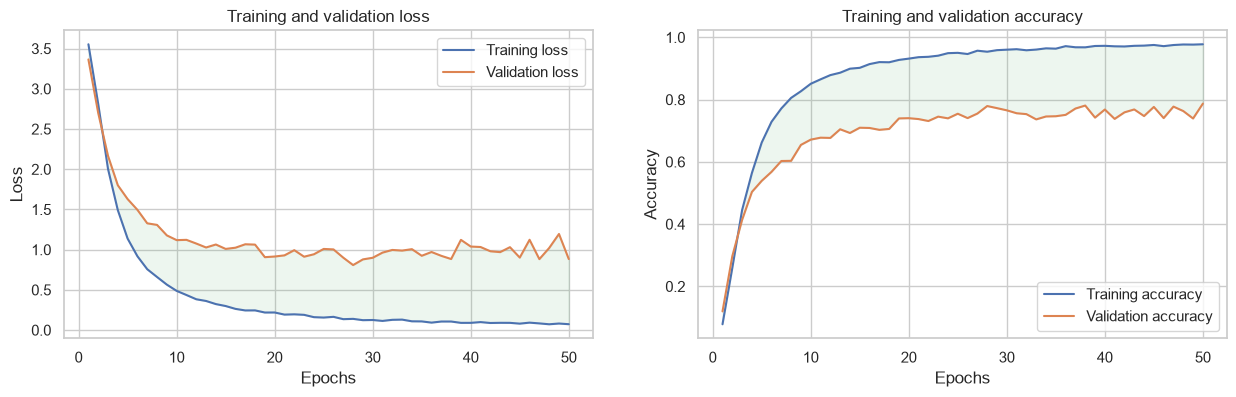

In [11]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(acc) + 1)

plt.figure(figsize=(15,4))

ax1 = plt.subplot(1, 2, 1)
plt.plot(epochs, loss, label='Training loss')
plt.plot(epochs, val_loss, label='Validation loss')
plt.fill_between(epochs, loss,val_loss,color='g',alpha=.1)

plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

ax2 = plt.subplot(1, 2, 2)
plt.plot(epochs, acc, label='Training accuracy')
plt.plot(epochs, val_acc, label='Validation accuracy')
plt.fill_between(epochs, acc,val_acc,color='g',alpha=.1)
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


Run the `classification_report` function below to build a text report showing the main classification metrics for your model:

In [13]:
# Index batches explicitly: labels, images, and predictions retain identical order.
y_true = val_ds.classes.copy()
y_prob = np.concatenate([model(val_ds[i][0], training=False).numpy()
                         for i in range(len(val_ds))], axis=0)
y_pred = y_prob.argmax(axis=1)
assert len(y_true) == len(y_pred) == val_ds.samples
print(classification_report(y_true, y_pred, labels=np.arange(num_classes),
                            target_names=class_names, zero_division=0))
print('Accuracy:', accuracy_score(y_true, y_pred))
print('Balanced accuracy:', balanced_accuracy_score(y_true, y_pred))


                                 precision    recall  f1-score   support

              bicycles_crossing       0.90      0.62      0.73       113
                     bumpy_road       1.00      0.98      0.99       124
              children_crossing       0.80      0.98      0.88       187
    dangerous_curve_to_the_left       0.72      0.66      0.69        79
   dangerous_curve_to_the_right       0.76      0.74      0.75       129
                   dont_go_left       0.96      0.83      0.89        29
          dont_go_left_or_right       0.80      1.00      0.89         4
                  dont_go_right       1.00      0.60      0.75        20
               dont_go_straight       1.00      1.00      1.00        12
        dont_overtake_from_left       0.96      0.81      0.88        27
                   double_curve       0.86      0.64      0.73       105
    end_of_no_passing_by_trucks       0.86      0.78      0.81        76
end_of_speed_and_passing_limits       0.68      0.

Run the  next cell to create a confusion matrix function `plot_confusion_matrix`.

In [14]:
def plot_confusion_matrix(cm, classes,
                        normalize=False,
                        title='Confusion matrix',
                        cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    vmax = cm.max()
    if normalize:
        title = 'Confusion matrix (normalized)'
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        cm = [[int(j*100) for j in i ] for i in cm]
        cm =np.array(cm)
        vmax = 100
        
    plt.figure(figsize=(14,14))

    im = plt.imshow(cm, interpolation='nearest', cmap=cmap, vmin=0.0, vmax=vmax)
    plt.title(title)
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=90)
    plt.yticks(tick_marks, classes)
    
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
            horizontalalignment="center",
            color="white" if cm[i, j] > thresh else "black")

    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.colorbar(im,fraction=0.046, pad=0.04)


Let's now create the confusion matrix.

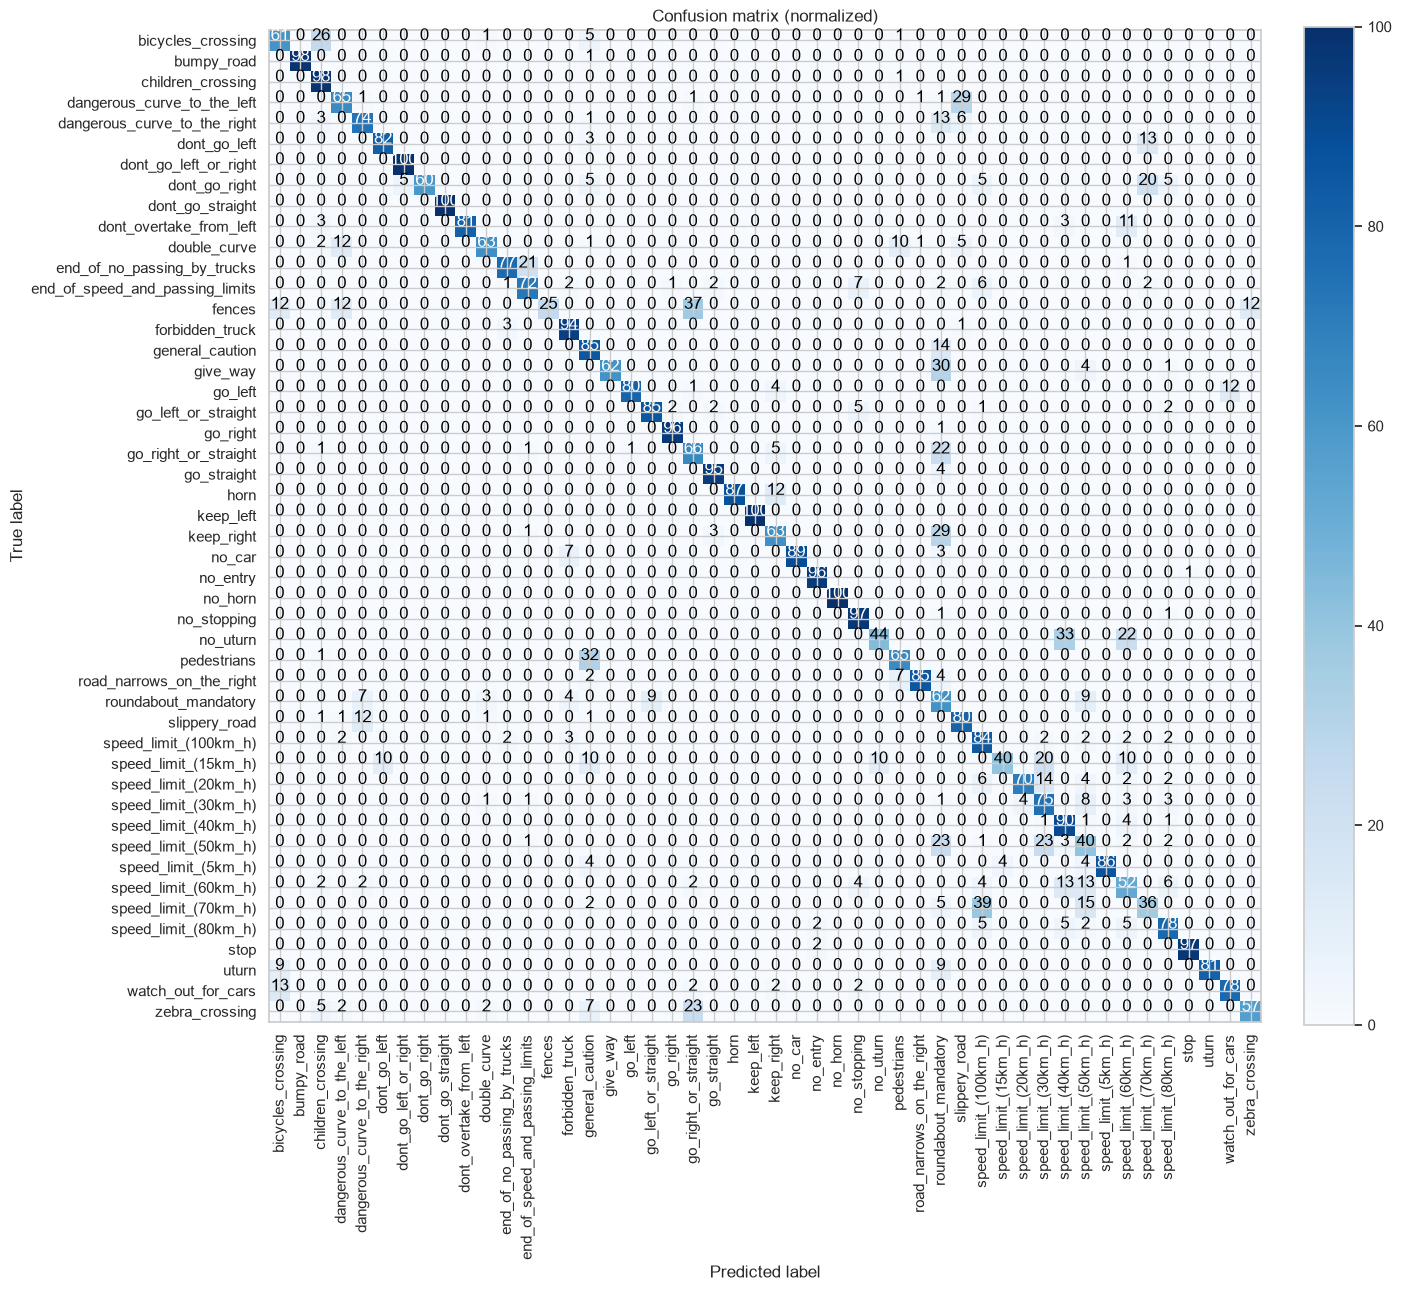

In [16]:
cnf_matrix = confusion_matrix(y_true, y_pred)
plot_confusion_matrix(cm=cnf_matrix, classes=class_names, title='Confusion Matrix', normalize=True)


## <span style="color:red"><b>TASK 2</b></span>


Examine the confusion matrix and provide an observation-based description of its content and patterns.


## TASK 2 — Confusion-matrix observations

**Observed in the saved run:** 2,779 of 3,846 images were correctly classified (72.26%). The matrix has a visible diagonal but also substantial off-diagonal errors, particularly among speed-limit classes and some directional signs. The largest individual error pair is `keep_right` → `roundabout_mandatory` (64 images). Recall for `speed_limit_(15km_h)` is only 10%, while `dont_go_left_or_right` reaches 100%; perfect recall on a small class should not be interpreted as proof of reliability.

Rows represent true labels and columns represent predictions. Diagonal cells are correct classifications; off-diagonal cells identify specific mistakes. Row normalization makes the diagonal a per-class recall percentage, avoiding the visual dominance of larger classes. The following answer reports the actual diagonal performance and largest error pairs. Similar appearance is a possible explanation for confusion, but it must be checked against the images rather than inferred from counts alone.



***


Let's now have a look at miss-classified examples by your model:

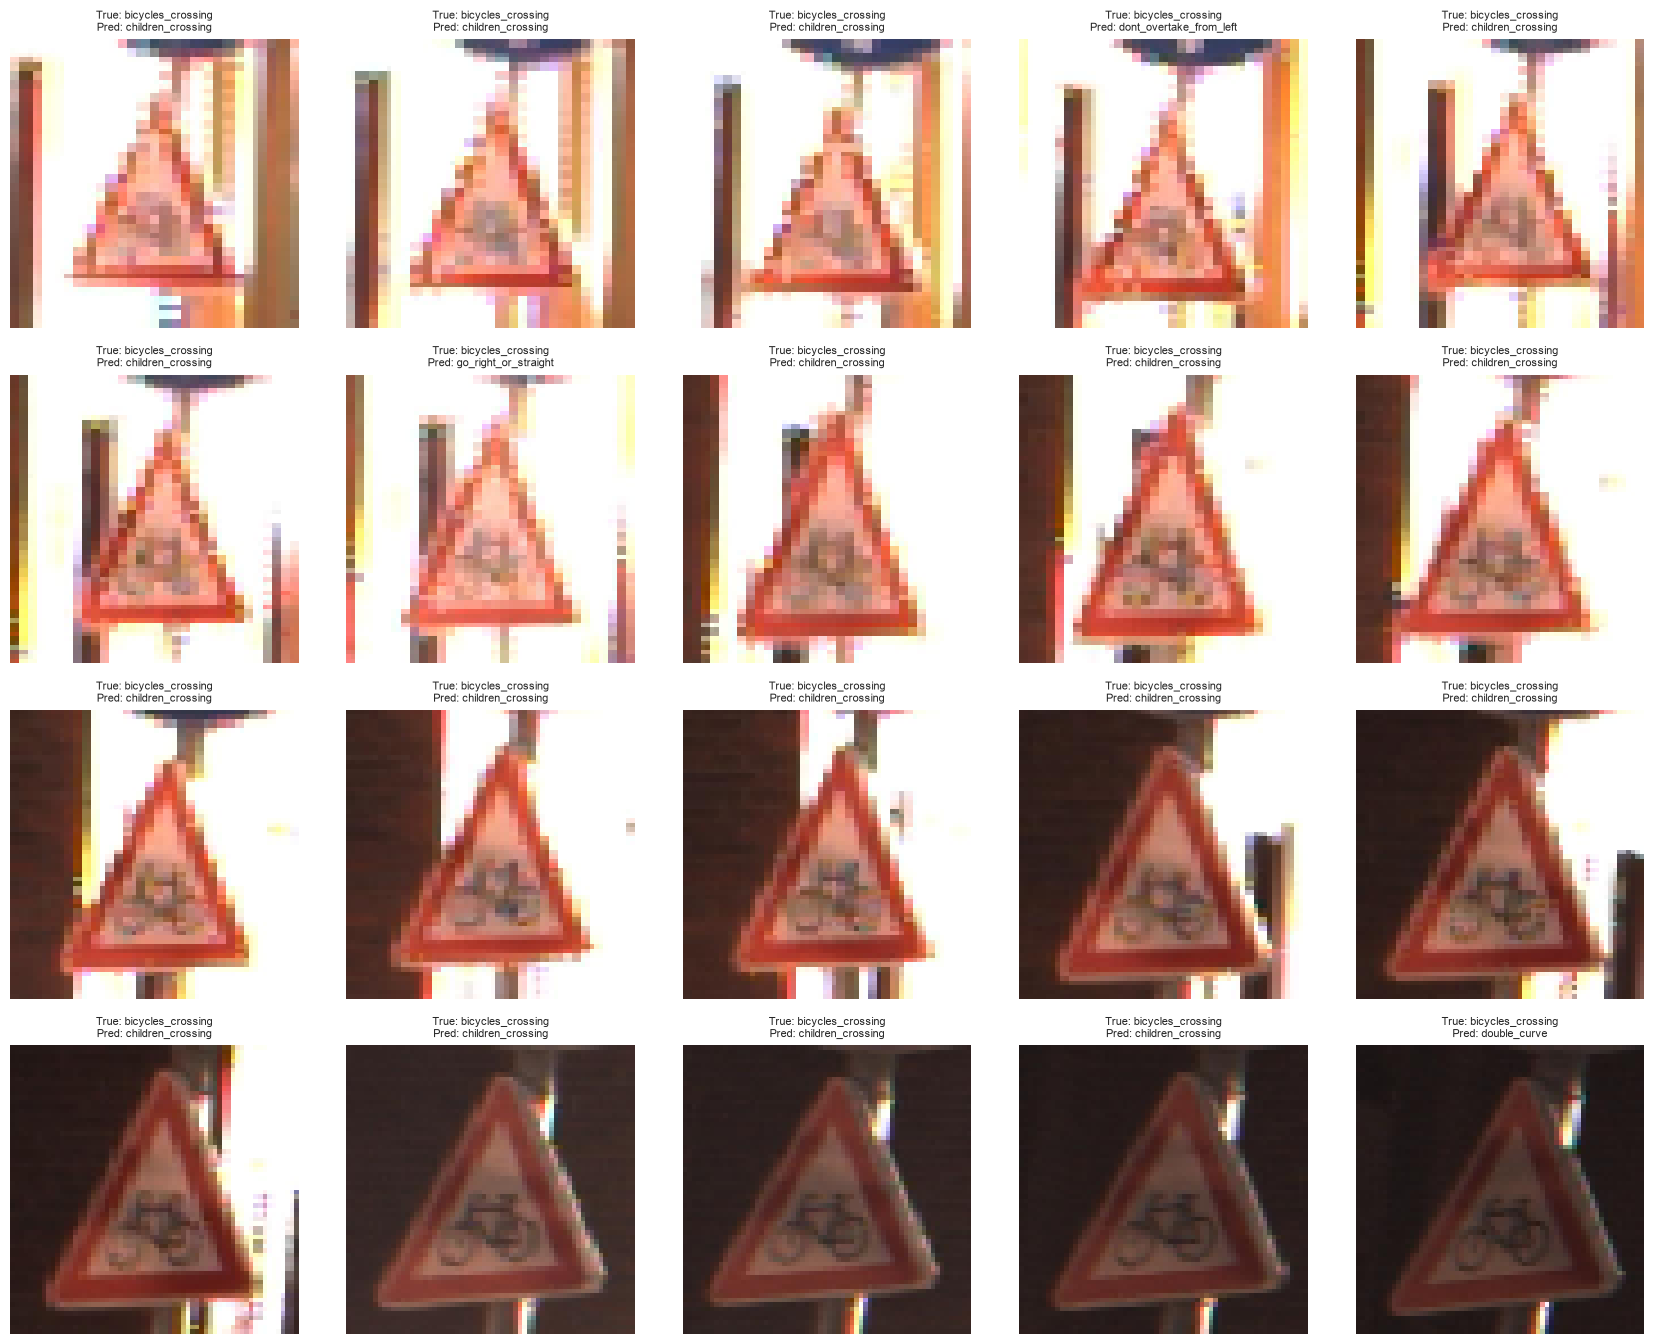

In [18]:
# A bounded selection replaces the original potentially infinite while-loop.
wrong_indices = np.flatnonzero(y_pred != y_true)[:20]
if len(wrong_indices) == 0:
    print('No misclassified validation examples.')
else:
    fig, axes = plt.subplots(int(np.ceil(len(wrong_indices)/5)), 5,
                             figsize=(17, 3.4*np.ceil(len(wrong_indices)/5)), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, idx in zip(axes.flat, wrong_indices):
        img = keras.utils.load_img(val_ds.filepaths[idx], target_size=image_size)
        ax.imshow(img)
        ax.set_title(f'True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}', fontsize=8)
    plt.tight_layout(); plt.show()


## TASK 3 — Safety risks from classification errors

**Connection to this run:** The 64 `keep_right` → `roundabout_mandatory` errors could give a planner the wrong directional context. The 10% recall for the 15 km/h class is another priority for inspection because failing to recognize a low speed limit could lead to excessive speed if the prediction directly controls driving. These are potential consequences, not observed vehicle behavior.

A traffic-sign mistake can change a vehicle's decision at exactly the wrong moment. For example, interpreting a stop sign as a permissive instruction could lead to entering an intersection without stopping; confusing speed limits could cause unsafe speed; and confusing directional restrictions could lead to an illegal turn. These are illustrative hazards, not claims that the plotted model made those exact mistakes. The displayed true/predicted pairs should determine the concrete hazards investigated.

Errors have unequal consequences: missing a restrictive sign can be more severe than slowing unnecessarily, although abrupt unnecessary braking can also be hazardous. Average accuracy therefore needs class-specific recall, examination of high-consequence errors, and testing under occlusion, poor illumination, weather, and distribution shift. Low uncertainty does not prove correctness: a model may be consistently wrong. A vehicle should combine sign recognition with temporal evidence and other sensors, and use a context-appropriate fallback when evidence is unreliable. This image-classification experiment alone cannot establish autonomous-driving safety.


# Monte carlo Dropout

Monte Carlo Dropout is a technique used in deep learning to estimate uncertainty in predictions made by a neural network. Regular dropout is a technique where during training, random neurons are "dropped out" by setting their outputs to zero. This prevents the network from becoming overly reliant on specific neurons and helps with generalization.

In the context of Monte Carlo Dropout, dropout is applied not only during training but also during inference (when making predictions). Instead of using a single forward pass to make a prediction, Monte Carlo Dropout involves performing multiple forward passes with dropout enabled. By averaging the predictions from these multiple passes, you can obtain a more robust estimate of uncertainty associated with each prediction.

Monte Carlo Dropout provides a way to model and quantify uncertainty in neural network predictions. It's particularly useful in tasks like Bayesian deep learning and uncertainty estimation for tasks such as image classification, where knowing the uncertainty of each prediction can be beneficial.


In [19]:
val_ds.reset()
val_ds.shuffle = False
# Initialize an empty list to store batches of data
X_val = []

# Iterate through all batches of data
for batch in val_ds:
    # Append the current batch to the list
    X_val.append(batch[0])  # Assuming batch[0] contains the data
    # Break the loop when all batches have been processed
    if val_ds.batch_index == 0:
        break

X_val = np.concatenate(X_val, axis=0)


## <span style="color:red"><b>TASK 4</b></span>

Iterate through the specified number of predictions (200) and utilize dropout when making predictions with the trained model.






In [20]:
# Task 4: training=True activates dropout during inference.
# Store hard class votes for every image and pass: final shape (N, 200).
# Accumulate probabilities separately, without storing a large (200,N,C) tensor.
N_MC = 200
mc_votes = np.empty((N_MC, len(X_val)), dtype=np.int32)
probability_sum = np.zeros((len(X_val), num_classes), dtype=np.float64)
@tf.function(input_signature=[tf.TensorSpec((None, *image_size, 3), tf.float32)])
def stochastic_predict(batch):
    return model(batch, training=True)
for t in trange(N_MC, desc='Monte Carlo dropout', ncols=100):
    for start in range(0, len(X_val), batch_size):
        stop = min(start + batch_size, len(X_val))
        probs = stochastic_predict(tf.convert_to_tensor(X_val[start:stop], dtype=tf.float32)).numpy()
        mc_votes[t, start:stop] = probs.argmax(axis=1)
        probability_sum[start:stop] += probs
mote_carlo_pred = mc_votes.T  # Original assignment variable name retained.
mean_mc_prob = probability_sum / N_MC
assert mote_carlo_pred.shape == (len(y_true), N_MC)
print('Vote array shape:', mote_carlo_pred.shape)


Monte Carlo dropout:   0%|                                                  | 0/200 [00:00<?, ?it/s]

Vote array shape: (3846, 200)


## <span style="color:red"><b>TASK 5</b></span>

In our approach, we leverage the concept of entropy as a fundamental tool to estimate uncertainty. By measuring the level of unpredictability within a given set of predictions, entropy provides a quantifiable metric that helps us gauge the uncertainty associated with each prediction. This utilization of entropy enables us to make more informed decisions and predictions in scenarios where uncertainty plays a pivotal role, fostering a deeper understanding of the underlying data dynamics and enhancing the reliability of our outcomes.


In [21]:
def get_entropy(vector):
    """Shannon entropy (nats) of empirical class votes, NOT raw label values."""
    vector = np.asarray(vector)
    if vector.ndim != 1 or vector.size == 0:
        raise ValueError('Expected a nonempty one-dimensional vector of class votes.')
    _, counts = np.unique(vector, return_counts=True)
    probabilities = counts / counts.sum()
    return float(-np.sum(probabilities * np.log(probabilities)))


## <span style="color:red"><b>TASK 6</b></span>

Find the most frequent prediction for each set of predictions in mote_carlo_pred and calculate the entropy of each set of predictions, storing both the most frequent predictions and the calculated entropies in separate lists (y_pred_most_freq and entropy, respectively).


In [22]:
# Task 6: loop over images, not over Monte Carlo passes.
y_pred_most_freq = []
entropy = []
for data in mote_carlo_pred:
    vote_counts = np.bincount(data, minlength=num_classes)
    y_pred_most_freq.append(int(vote_counts.argmax()))  # Ties: smallest class index.
    entropy.append(get_entropy(data))
y_pred_most_freq = np.asarray(y_pred_most_freq)
entropy = np.asarray(entropy)
y_pred_mc_mean = mean_mc_prob.argmax(axis=1)
predictive_entropy = -np.sum(mean_mc_prob * np.log(np.clip(mean_mc_prob, 1e-12, 1)), axis=1)
assert len(y_pred_most_freq) == len(entropy) == len(y_true)


Let's proceed to contrast the accuracy achieved by our model with that obtained through the utilization of the most frequently predicted value employing Monte Carlo dropout.




In [23]:
print('Accuracy of our model:', accuracy_score(y_pred, y_true))
print('Accuracy utilizing the most frequently predicted value employing Monte Carlo dropout:', 
      accuracy_score(y_pred_most_freq, y_true))


Accuracy of our model: 0.7870514820592823
Accuracy utilizing the most frequently predicted value employing Monte Carlo dropout: 0.8127925117004681


## TASK 7 — Comparing deterministic and MC-dropout performance

**Observed conclusion:** MC majority voting achieved 79.51% accuracy versus 72.26% for the deterministic model, an improvement of 7.25 percentage points. It corrected 366 previous errors but introduced 87 new errors, giving a net gain of 279 correct classifications. Averaging probabilities achieved 79.54%, only slightly higher than voting. Therefore MC inference helps on this validation split, but still leaves about one fifth of images incorrectly classified; it is not sufficient evidence of safe deployment.

The generated observation below compares the same validation images, labels, and trained weights. Majority voting may reduce sensitivity to individual dropout masks, but it can also remove useful information by discarding soft probabilities. It is therefore not guaranteed to outperform deterministic inference. Averaging probabilities is included as a supplementary comparison; the required result is majority-vote accuracy. A small difference from one run does not establish a reliable general improvement; repeat seeds and evaluate on independent data. The main additional benefit is an uncertainty signal, with increased inference cost.


Let's now organize information about predictions, whether they are correct or incorrect, their associated entropy values, and their confidence scores into a Pandas DataFrame for further analysis and visualization.

In [24]:
confidence_scores = np.max(y_prob, axis=1)
data = {'Prediction': np.array(['Correct' if x == y else 'Incorrect' for x, y in zip(y_pred, y_true)]), 
        'Entropy value': entropy,
        'Confidence score': confidence_scores}

df = pd.DataFrame(data)


Let's employ boxplots of the entropy and confidence score distributions to illustrate the distinction between accurate and erroneous predictions.


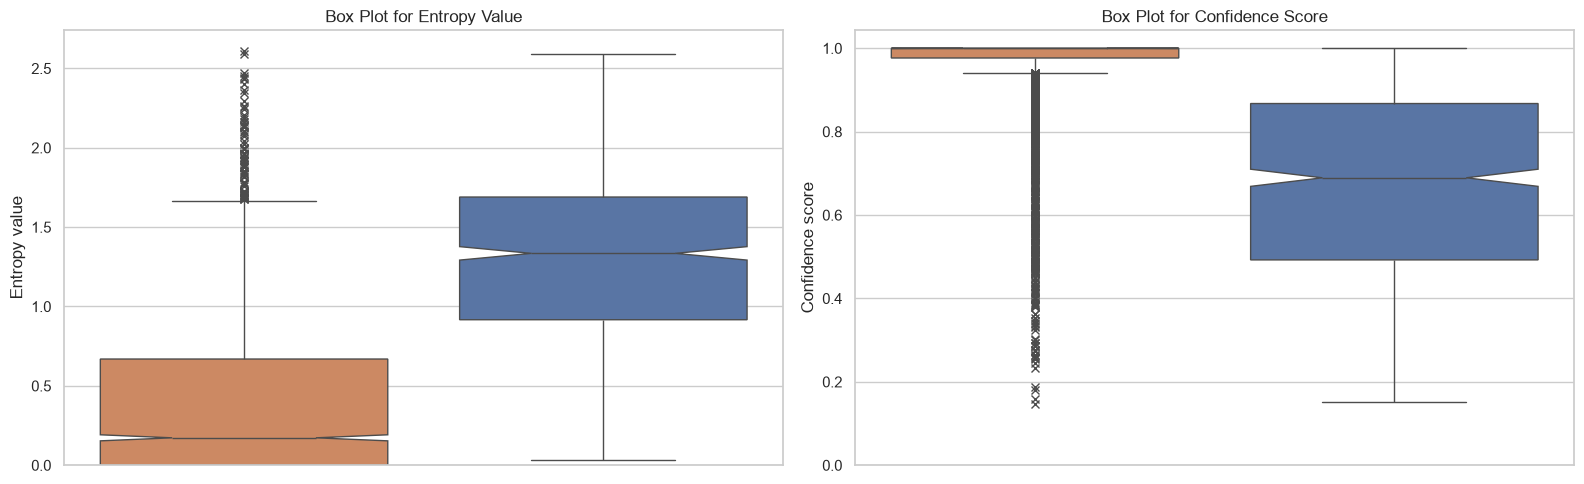

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Box plot for 'Entropy value'
sns.boxplot(data=df, 
            x='Prediction', 
            y='Entropy value', 
            hue='Prediction', 
            order=["Correct", "Incorrect"],
            notch=True, 
            showcaps=True,
            flierprops={"marker": "x"},
            ax=axes[0])  # Put it in the first subplot (axes[0])

axes[0].set_xticklabels([])
axes[0].set(xlabel='')
axes[0].set(ylim=(0, None))
axes[0].set_title('Box Plot for Entropy Value')

# Box plot for 'Confidence score'
sns.boxplot(data=df, 
            x='Prediction', 
            y='Confidence score', 
            hue='Prediction', 
            order=["Correct", "Incorrect"],
            notch=True, 
            showcaps=True,
            flierprops={"marker": "x"},
            ax=axes[1])  # Put it in the second subplot (axes[1])

axes[1].set_xticklabels([])
axes[1].set(xlabel='')
axes[1].set(ylim=(0, None))
axes[1].set_title('Box Plot for Confidence Score')

# Adjust the layout
plt.tight_layout()

# Show the subplots
plt.show()


## TASK 8 — Interpreting entropy and confidence

**Observed conclusion:** Incorrect predictions had much higher median vote entropy (1.253 nats) than correct predictions (0.135 nats). Their median baseline confidence was lower (0.826 versus approximately 1.000). Entropy ranked errors better in this run (AUROC 0.913) than 1 − confidence (0.869). The overlapping distributions and high-confidence mistakes show that neither measure perfectly separates correct and incorrect cases. Entropy is useful for prioritizing uncertain decisions, but it cannot certify correctness.

Entropy reflects disagreement between stochastic predictions, whereas the baseline confidence is the maximum probability from one deterministic softmax vector. If incorrect predictions have higher entropy and lower confidence, these measures help rank possible errors. The boxplots also show overlap: a useful trend does not mean every high-entropy image is wrong or every low-entropy image is correct. High-confidence errors demonstrate why a softmax score should not be treated as a calibrated probability of correctness. The following observation uses the actual medians and error-detection AUROC. AUROC above 0.5 indicates better-than-random ranking of errors for the chosen score; it does not validate any particular operational cutoff.


Let's proceed to visualize the achieved accuracy against the proportion of predicted examples from the validation set, considering different entropy cutoff values.



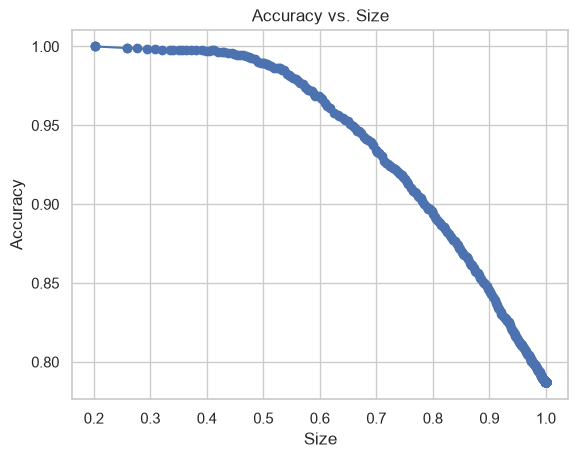

In [26]:
accuracy = []
size = []
for v in [x * 0.01 for x in range(1, 410)]:
    df2 = df[(df['Entropy value']<v)]
    count = len(df2[df2['Prediction'] == 'Correct'])
    accuracy.append(count/len(df2))
    size.append(len(df2)/len(df))
# Create a line plot
plt.plot(size, accuracy, marker='o', linestyle='-')

# Set labels for x and y axes
plt.ylabel('Accuracy')
plt.xlabel('Size')

# Set a title for the plot
plt.title('Accuracy vs. Size')

# Show the plot
plt.grid(True)  # Add grid lines
plt.show()

## TASK 9 — Accuracy–coverage trade-off

**Observed conclusion:** Accepting only zero-vote-entropy examples retained 856 of 3,846 images (22.26% coverage) and achieved 99.88% baseline selective accuracy. This is substantially above 72.26% at full coverage, but rejects 2,990 images (77.74%) and still retains one wrong prediction. Thus uncertainty filtering improves reliability on the accepted subset at the cost of many unresolved decisions. The saved curve shows this trade-off for both baseline and MC predictions; an operational system needs a tested fallback for rejected cases.

Coverage is the fraction of all validation examples retained after filtering. Selective accuracy is the fraction correct **among retained examples**. A strict entropy cutoff can improve selective accuracy when uncertainty ranks errors well, but it also rejects images requiring a fallback. It does not improve the original classifier on every image, and accuracy need not change monotonically. Tied zero-entropy images can prevent obtaining arbitrarily small nonzero coverage.

The result below compares the lowest-entropy acceptance group with full coverage. Very small accepted groups give unstable estimates, so counts must accompany percentages. Cutoff selection on these same validation results is exploratory; a deployed cutoff would need separate calibration and independent test evaluation, with class-specific coverage and the consequences of rejected decisions assessed.


## TASK 10 — Alternative: deep ensembles with uncertainty-based abstention

An alternative is a **deep ensemble**: independently train several CNNs with different random initializations and minibatch orders, then average their predicted probability vectors. For $M$ models, use $\bar p(y\mid x)=M^{-1}\sum_m p_m(y\mid x)$ and predict the class with the largest averaged probability. Compute entropy of this average to measure predictive uncertainty; model disagreement supplies additional information. Unlike MC dropout, which samples masks within one fitted network, the ensemble contains separately fitted networks ([Lakshminarayanan et al., 2017](https://papers.nips.cc/paper/7219-simple-and-scalable-predictive-uncertainty-estimation-using-deep-ensembles)).

A practical experiment would train five copies of the same architecture using the training data, set an uncertainty threshold on a separate calibration split, and assess accuracy, macro recall, calibration, error detection, and accuracy versus coverage on an untouched test set. Accept sufficiently certain predictions and route uncertain cases to a context-appropriate fallback. Compare at matched coverage and report computation time, since independent training and multiple forward passes cost more memory and computation.

Averaging can reduce errors specific to an individual fit, and abstention can improve the reliability of accepted decisions. Neither effect is guaranteed for this dataset without an experiment. Models can share systematic errors, including confident mistakes on unfamiliar signs. Ensembles should therefore complement diverse training data, distribution-shift testing, and a broader safety design. This technique is proposed here; no ensemble performance is claimed without training it.


# Acknowledgment

Please feel free contact me if you identify errors, bugs, or issue with this assignment.

**Author:** [Mohamed Reda Bouadjenek](https://rbouadjenek.github.io/), Lecturer of Applied Artificial Intelligence, 

**Institution:** Deakin University, School of Information Technology, Faculty of Sci Eng & Built Env

**Adress:** Locked Bag 20000, Geelong, VIC 3220

**Phone:** +61 3 522 78380

**Email:** reda.bouadjenek@deakin.edu.au

**www.deakin.edu.au**
